# Indie Games on Steam: Exploratory Analysis (by Rodrigo Gonçalves)

This notebook explores the Steam games catalogue, focusing on indie games.
It is the first part of a two-part project:

1. **Exploration (this notebook):** clean the data and understand the indie game market on Steam: prices, genres, reviews and how they have changed over time.
2. **AI in indie games (next):** add Steam's "AI Generated Content Disclosure" to each game and investigate how games that disclose AI use compare to those that don't.

**Data:** [Steam Games Dataset](https://www.kaggle.com/datasets/fronkongames/steam-games-dataset) by FronkonGames, collected from the Steam API and Steam Spy.

## 1. Loading the data

The original CSV file has a header bug: the column name `DiscountDLC count` is actually two columns (`Discount` and `DLC count`).
Because the header has one name fewer than each data row, pandas treats the first column (AppID) as the index and every column name up to that point is shifted by one, e.g. the `Price` column would actually contain discount values.

To fix this, I read the header separately, split the broken name into two, and load the data with the corrected column names.
I fix this in code rather than editing the file, so the correction is visible and still works if the dataset is updated.

In [ ]:
import pandas as pd

# 1. Ler só o cabeçalho
cols = pd.read_csv("data/games.csv", nrows=0).columns.tolist()

# 2. Partir o nome errado em dois
i = cols.index("DiscountDLC count")
cols[i:i+1] = ["Discount", "DLC count"]

# 3. Ler os dados com os nomes corrigidos
df = pd.read_csv("data/games.csv", header=0, names=cols, index_col=False)

print(df.shape)
df.head()

(125855, 40)


,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,Discount,DLC count,About the game,...,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Categories,Genres,Tags,Screenshots,Movies
0,2539430,Black Dragon Mage Playtest,"Aug 1, 2023",0 - 0,0,0,0.00,0,0,NaN,...,0,0,0,NaN,NaN,NaN,NaN,NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
1,496350,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",0 - 20000,0,0,5.24,65,0,"Springtime, April: when the cherry trees come ...",...,0,8,0,minori,MangaGamer,"Single-player,Steam Trading Cards,Steam Cloud,...",Adventure,"Adventure,Visual Novel,Anime,Cute",https://shared.akamai.steamstatic.com/store_it...,NaN
2,1034400,Mystery Solitaire The Black Raven,"May 6, 2019",0 - 20000,0,0,4.99,0,0,"Immerse yourself in the most beloved, mystical...",...,0,0,0,Somer Games,8floor,"Single-player,Family Sharing",Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec...",https://shared.akamai.steamstatic.com/store_it...,NaN
3,3292190,버튜버 파라노이아 - Vtuber Paranoia,"Oct 31, 2024",0 - 20000,1,0,8.99,0,1,"synopsis 'Hello, I'm Hiyoro, a new YouTuber!' ...",...,0,0,0,유진게임즈,유진게임즈,"Single-player,Steam Achievements,Family Sharing","Casual,Indie,Simulation",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
4,3631080,Maze Quest VR,"Apr 24, 2025",0 - 20000,0,0,4.99,0,0,Its not just a Maze; its a Quest! Enter the ca...,...,0,0,0,Reality Expanded LLC,Reality Expanded LLC,"Single-player,VR Only,Steam Leaderboards,Famil...","Action,Early Access",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN


## 2. First look at the data

Checking each column's data type and how many values are present.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 125855 entries, 0 to 125854
Data columns (total 40 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   AppID                       125855 non-null  int64  
 1   Name                        125854 non-null  str    
 2   Release date                125855 non-null  str    
 3   Estimated owners            125855 non-null  str    
 4   Peak CCU                    125855 non-null  int64  
 5   Required age                125855 non-null  int64  
 6   Price                       125855 non-null  float64
 7   Discount                    125855 non-null  int64  
 8   DLC count                   125855 non-null  int64  
 9   About the game              117393 non-null  str    
 10  Supported languages         125855 non-null  str    
 11  Full audio languages        125855 non-null  str    
 12  Reviews                     12181 non-null   str    
 13  Header image             

## 3. Missing values

Percentage of missing values per column, sorted from most to least missing.

In [4]:
(df.isna().mean() * 100).sort_values(ascending=False).round(1)

Movies                        100.0
Score rank                    100.0
Metacritic url                 96.6
Reviews                        90.3
Notes                          81.5
Website                        59.9
Support url                    56.1
Tags                           33.8
Support email                  18.0
Categories                      7.1
Publishers                      7.1
About the game                  6.7
Developers                      6.7
Genres                          6.7
Screenshots                     4.8
Header image                    0.1
Name                            0.0
Discount                        0.0
Required age                    0.0
Price                           0.0
Estimated owners                0.0
Release date                    0.0
AppID                           0.0
Peak CCU                        0.0
Positive                        0.0
User score                      0.0
Metacritic score                0.0
Linux                       

## 4. Investigating rows without a genre

`About the game`, `Developers` and `Genres` are all missing in about 6.7% of rows, which suggests they are the same rows.

Results:
- 8,423 games have no genre.
- Of these, 8,290 also have no developer and 8,282 have no description.
- Inspecting examples shows they are almost all **playtests**: free test builds with zero reviews, not actual games.

In [5]:
missing_genres = df["Genres"].isna()
print("Sem género:", missing_genres.sum())
print("Destes, também sem developer:", (missing_genres & df["Developers"].isna()).sum())
print("Destes, também sem descrição:", (missing_genres & df["About the game"].isna()).sum())
df[missing_genres][["Name", "Release date", "Price", "Positive", "Negative"]].head(10)

Sem género: 8423
Destes, também sem developer: 8290
Destes, também sem descrição: 8282


,Name,Release date,Price,Positive,Negative
0,Black Dragon Mage Playtest,"Aug 1, 2023",0.0,0,0
10,Codename: Warlock Playtest,"Mar 25, 2022",0.0,0,0
24,CyberVault Playtest,"Mar 8, 2023",0.0,0,0
25,A Night In Omar's Burger Playtest,"Oct 4, 2023",0.0,0,0
51,Dark and Deep Playtest,"Mar 20, 2024",0.0,0,0
97,Bill's Misfortune Playtest,"Jan 17, 2024",0.0,0,0
102,QUADRA CLASH Playtest,"Apr 19, 2025",0.0,0,0
116,Descendance Playtest,"Sep 24, 2025",0.0,0,0
118,Red Solstice 2: Survivors Playtest,"Feb 25, 2021",0.0,0,0
137,Pain Party Playtest,"Sep 10, 2021",0.0,0,0


## 5. Dropping unused columns

Removed columns that are almost entirely empty or irrelevant to this analysis:
- `Movies`, `Score rank`, `Metacritic url`: 97–100% missing.
- `Reviews`: press review excerpts, only present for about 10% of games (mostly large titles). Not to be confused with `Positive` / `Negative`, the user review counts, which are complete.
- `Notes`: content warnings, 81% missing.
- `Website`, `Support url`, `Support email`: contact details, not useful for analysis.

In [6]:
cols_to_drop = ["Movies", "Score rank", "Metacritic url", "Reviews", "Notes",
                "Website", "Support url", "Support email"]
df = df.drop(columns=cols_to_drop)
print(df.shape)

(125855, 32)


## 6. Removing rows without a genre and remaining playtests

Rows without a genre are removed, since they are mostly playtests.
I then check whether any playtests remain that do have a genre.

12 remain, all free with zero reviews, so they are removed as well.

**Note on defining "indie":** my project uses Steam's `Indie` genre to identify indie games.
This label is chosen by developers themselves and is not verified, so some larger studios may use it and some indie developers may not.
It is not a perfect definition, but it is the best one available in this data.

In [7]:
# Apagar linhas sem género
df = df[df["Genres"].notna()]
print("Depois de apagar sem género:", df.shape)

# Ainda há playtests?
is_playtest = df["Name"].str.contains("playtest", case=False, na=False)
print("Playtests restantes:", is_playtest.sum())
df[is_playtest][["Name", "Genres", "Price", "Positive", "Negative"]].head(10)

Depois de apagar sem género: (117432, 32)
Playtests restantes: 12


,Name,Genres,Price,Positive,Negative
4674,DUELANT Online Playtest,"Action,Indie",0.0,0,0
7332,The Dusk Alliance Playtest,"Action,Adventure",0.0,0,0
7553,Cyberpunk Sister Playtest,"Action,Indie",0.0,0,0
7756,Mo The Moai Playtest,"Action,Adventure,Indie",0.0,0,0
23251,Modulus Playtest,Simulation,0.0,0,0
28992,Project Three Playtest,"Action,Adventure,Indie",0.0,0,0
36118,Silent Pathways Playtest,"Adventure,Indie",0.0,0,0
48415,NBB.EXE Playtest,"Action,Adventure",0.0,0,0
51572,A2C:Ayry seems to be playtesting a 2D runner s...,"Action,Casual,Indie,Free To Play",0.0,0,0
56928,Bless Unleashed Playtest,"Action,Free To Play,Massively Multiplayer,RPG",0.0,0,0


## 7. How many reviews do games have?

Approval percentages are unreliable for games with very few reviews: a game with 1 positive review has 100% approval, while one with 9,000 positive and 1,000 negative has 90%.

Before comparing games by approval, I check how many reviews games typically have, grouped into ranges rather than averaged, since a few very popular games would distort the mean.

In [8]:
# Apagar os playtests restantes
df = df[~is_playtest]
print("Depois de apagar playtests:", df.shape)

# Total de críticas por jogo
df["Total reviews"] = df["Positive"] + df["Negative"]

# Quantos jogos em cada faixa
bins = [-1, 0, 9, 49, 499, float("inf")]
labels = ["0", "1-9", "10-49", "50-499", "500+"]
pd.cut(df["Total reviews"], bins=bins, labels=labels).value_counts().sort_index()

Depois de apagar playtests: (117420, 32)


Total reviews
0         34579
1-9       26276
10-49     26024
50-499    20062
500+      10479
Name: count, dtype: int64

**Findings:** over half of Steam games (51%) have fewer than 10 reviews, and almost a third (29%) have none.

**Decision:**
- For questions about **approval** (share of positive reviews), only games with **at least 10 reviews** are used (about 56,500 games).
- For questions about the **market** (releases per year, genres, prices), **all games** are used.

**Limitation:** keeping only games with 10+ reviews favours games that had at least some success (survivorship bias). The threshold of 10 is a reasonable starting point; I will check whether conclusions change with a different threshold.

## 8. Preparing dates and identifying indie games

Two new columns are needed before looking at trends over time:

- **Year:** `Release date` is stored as text (e.g. "Aug 1, 2023"), so it is converted to a proper date and the year is extracted. Some dates use other formats (e.g. "Aug 2023"), so mixed formats are allowed; any date that cannot be converted is marked as missing and counted.
- **Is indie:** a game is marked as indie if `Indie` is one of its genres. Genres are split into a list and checked for an exact match, so similar names (e.g. a hypothetical "Indie Horror") are not counted by mistake.

In [9]:
# Converter texto em data
df["Release date"] = pd.to_datetime(df["Release date"], format="mixed", errors="coerce")
print("Datas que não deu para converter:", df["Release date"].isna().sum())

df["Year"] = df["Release date"].dt.year

# Marcar jogos indie
df["Is indie"] = df["Genres"].str.split(",").apply(lambda g: "Indie" in g)
print("Jogos indie:", df["Is indie"].sum(), "de", len(df))

Datas que não deu para converter: 0
Jogos indie: 82877 de 117420


**Result:** all dates were converted successfully. 82,877 of 117,420 games (70.6%) are labelled as indie.

This share is very high. It likely reflects both how many small developers publish on Steam and how loosely the self-chosen `Indie` label is applied.

## 9. Releases per year: all games vs indie games

How many games are released on Steam each year, and how much of that growth comes from indie games?

The most recent year in the dataset may be incomplete (depending on when the data was collected), so I check the latest release date first and exclude any partial year from the chart.

Data mais recente: 2026-12-01 00:00:00


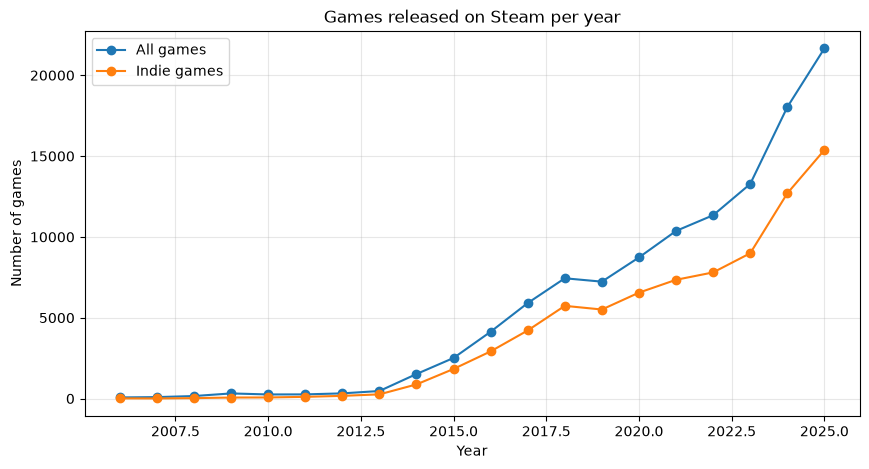

,total,indie,indie_share
Year,,,
2018,7441,5735,77.1
2019,7232,5508,76.2
2020,8731,6553,75.1
2021,10370,7347,70.8
2022,11342,7804,68.8
2023,13276,8989,67.7
2024,18030,12695,70.4
2025,21659,15378,71.0


In [10]:
import matplotlib.pyplot as plt

print("Data mais recente:", df["Release date"].max())

per_year = df.groupby("Year").agg(
    total=("AppID", "count"),
    indie=("Is indie", "sum"),
)
per_year["indie_share"] = per_year["indie"] / per_year["total"] * 100

last_full_year = 2025
per_year = per_year.loc[2006:last_full_year]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(per_year.index, per_year["total"], label="All games", marker="o")
ax.plot(per_year.index, per_year["indie"], label="Indie games", marker="o")
ax.set_title("Games released on Steam per year")
ax.set_xlabel("Year")
ax.set_ylabel("Number of games")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

per_year.round(1).tail(8)

## 10. Fixing two issues found in the chart

**Unreleased games:** the most recent release date in the dataset is in the future (December 2026), which means some entries are upcoming games with planned release dates, even though the dataset describes itself as containing only released games. These are removed.

**Year axis:** `Year` was stored as a decimal number, which caused labels like "2007.5" on the chart. It is converted to an integer.

In [11]:
today = pd.Timestamp("2026-11-14")
future = df["Release date"] > today
print("Jogos ainda por lançar:", future.sum())
df = df[~future]

df["Year"] = df["Year"].astype(int)
print(df.shape)

Jogos ainda por lançar: 1
(117419, 35)


**Findings:**
Releases grew from a few hundred per year before 2013 to over 21,600 in 2025.

Two periods of acceleration stand out: around 2013–2014, which coincides with Steam opening its store to small developers (Steam Greenlight, launched in 2012), and **2023–2025, when releases rose by 63% in two years**, the steepest increase in the chart.

The indie share fell from 77% (2018) to 68% (2023) and rose back to 71% in 2025.

**Hypothesis for part 2:** the recent surge in releases may be partly linked to generative AI tools making games faster to produce. This data contains no information about AI, so this cannot be concluded here; it will be tested in the second part of the project.

**Limitation:** the dataset only includes games currently on the store, so delisted games are missing and older years may be slightly underestimated.